In [1]:
import numpy as np
import pandas as pd


In [2]:
df = pd.read_csv("spam.csv", encoding="latin-1")
df.sample(5)

,v1,v2,Unnamed: 2,Unnamed: 3,Unnamed: 4
2198,ham,I'm in a movie. Call me 4 wat?,NaN,NaN,NaN
1769,ham,Ha... Both of us doing e same thing. But i got...,NaN,NaN,NaN
2420,ham,Oic... Then better quickly go bathe n settle d...,NaN,NaN,NaN
5030,ham,Hey... Very inconvenient for your sis a not huh?,NaN,NaN,NaN
5527,ham,"Total disappointment, when I texted you was th...",NaN,NaN,NaN


In [3]:
# 1.Data cleaning
# 2.EDA
# 3.Text preprocessing
# 4.model building
# 5.evaluation
# 6.improvement
# 7.website
# 8.Deploy


### 1.DATA CLEANING

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5572 entries, 0 to 5571
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   v1          5572 non-null   object
 1   v2          5572 non-null   object
 2   Unnamed: 2  50 non-null     object
 3   Unnamed: 3  12 non-null     object
 4   Unnamed: 4  6 non-null      object
dtypes: object(5)
memory usage: 217.8+ KB


In [5]:
## drop last 3 col
df.drop(columns=['Unnamed: 2','Unnamed: 3','Unnamed: 4'],inplace=True)

In [6]:
df.sample(5)

,v1,v2
2638,ham,Am in gobi arts college
717,ham,Book which lesson? then you msg me... I will c...
1728,ham,As per your request 'Maangalyam (Alaipayuthe)'...
2261,ham,Did you show him and wot did he say or could u...
5012,ham,"Uncle G, just checking up on you. Do have a re..."


In [7]:
## renaming the col
df.rename(columns={'v1':'Target','v2':'Text'},inplace=True)
df.sample(5)

,Target,Text
4448,spam,Urgent UR awarded a complimentary trip to Euro...
4146,ham,Pls help me tell sura that i'm expecting a bat...
5504,ham,Wait . I will msg after &lt;#&gt; min.
2992,ham,So i'm doing a list of buyers.
3687,ham,I'll meet you in the lobby


In [8]:
from sklearn.preprocessing import LabelEncoder
encoder=LabelEncoder()

In [9]:
df['Target']=encoder.fit_transform(df['Target'])

In [10]:
df.sample(5)

,Target,Text
846,0,My stomach has been thru so much trauma I swea...
3762,0,K.i will send in &lt;#&gt; min:)
22,0,So Ì_ pay first lar... Then when is da stock c...
2598,0,Okie... Thanx...
2032,0,"Yes, i'm small kid.. And boost is the secret o..."


In [11]:
df.isnull().sum()

Target    0
Text      0
dtype: int64

In [12]:
df.duplicated().sum()

np.int64(403)

In [13]:
df.drop_duplicates(keep='first',inplace=True)
df.duplicated().sum()

np.int64(0)

In [14]:
df.shape

(5169, 2)

### 2.EDA

In [15]:
df['Target'].value_counts()

Target
0    4516
1     653
Name: count, dtype: int64

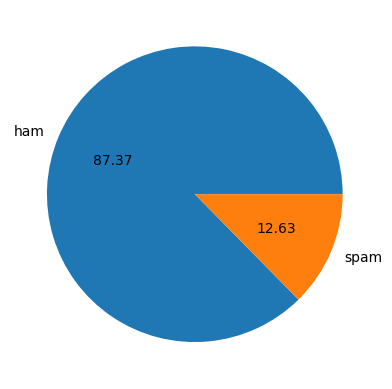

In [16]:
import matplotlib.pyplot as plt
plt.pie(df['Target'].value_counts(),labels=['ham','spam'],autopct="%0.2f")
plt.show()

In [17]:
## data is imbalanced

In [18]:
import nltk

In [19]:
nltk.download('punkt_tab')

[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\hp\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


True

In [20]:
## number of charater in each text 
df['num_character']=df['Text'].apply(len)

In [21]:
## number of word in each text 
df['num_word']=df['Text'].apply(lambda x:len(nltk.word_tokenize(x)))

In [22]:
df.head()

,Target,Text,num_character,num_word
0,0,"Go until jurong point, crazy.. Available only ...",111,24
1,0,Ok lar... Joking wif u oni...,29,8
2,1,Free entry in 2 a wkly comp to win FA Cup fina...,155,37
3,0,U dun say so early hor... U c already then say...,49,13
4,0,"Nah I don't think he goes to usf, he lives aro...",61,15


In [23]:
## number of sentence in each text 
df['num_sentence']=df['Text'].apply(lambda x:len(nltk.sent_tokenize(x)))

In [24]:
df.head()

,Target,Text,num_character,num_word,num_sentence
0,0,"Go until jurong point, crazy.. Available only ...",111,24,2
1,0,Ok lar... Joking wif u oni...,29,8,2
2,1,Free entry in 2 a wkly comp to win FA Cup fina...,155,37,2
3,0,U dun say so early hor... U c already then say...,49,13,1
4,0,"Nah I don't think he goes to usf, he lives aro...",61,15,1


In [25]:
df[['num_character','num_word','num_sentence']].describe()

,num_character,num_word,num_sentence
count,5169.000000,5169.000000,5169.000000
mean,78.977945,18.460437,1.965564
std,58.236293,13.334441,1.448541
min,2.000000,1.000000,1.000000
25%,36.000000,9.000000,1.000000
50%,60.000000,15.000000,1.000000
75%,117.000000,26.000000,2.000000
max,910.000000,220.000000,38.000000


In [26]:
## for ham
df[df['Target']==0][['num_character','num_word','num_sentence']].describe()

,num_character,num_word,num_sentence
count,4516.000000,4516.000000,4516.000000
mean,70.459256,17.128432,1.820195
std,56.358207,13.504730,1.383657
min,2.000000,1.000000,1.000000
25%,34.000000,8.000000,1.000000
50%,52.000000,13.000000,1.000000
75%,90.000000,22.000000,2.000000
max,910.000000,220.000000,38.000000


In [27]:
## for spam
df[df['Target']==1][['num_character','num_word','num_sentence']].describe()

,num_character,num_word,num_sentence
count,653.000000,653.000000,653.000000
mean,137.891271,27.672282,2.970904
std,30.137753,7.010932,1.488425
min,13.000000,2.000000,1.000000
25%,132.000000,25.000000,2.000000
50%,149.000000,29.000000,3.000000
75%,157.000000,32.000000,4.000000
max,224.000000,46.000000,9.000000


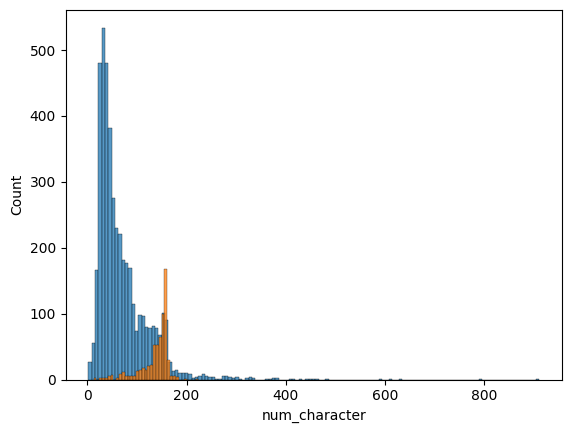

In [28]:
import seaborn as sns
plt.Figure(figsize=(12,8))
sns.histplot(df[df['Target']==0]['num_character'])
sns.histplot(df[df['Target']==1]['num_character'])
plt.show()

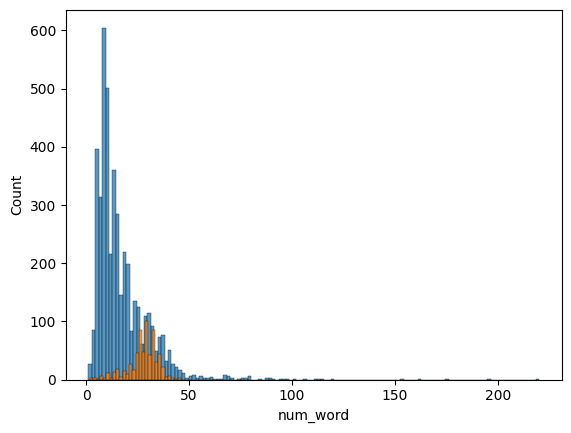

In [29]:
plt.Figure(figsize=(12,8))
sns.histplot(df[df['Target']==0]['num_word'])
sns.histplot(df[df['Target']==1]['num_word'])
plt.show()

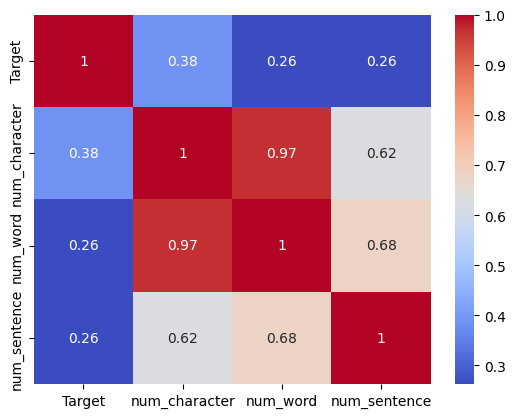

In [34]:
sns.heatmap(df.corr(numeric_only=True), annot=True, cmap='coolwarm')
plt.show()

### 3. Data Preprocessing

- Lowercase conversion
- Tokenization
- Removing special characters
- Removing stop words and punctuation
- Stemming

In [40]:
nltk.download('stopwords')
from nltk.corpus import stopwords
stop_word=stopwords.words('english')

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\hp\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


In [37]:
import string 
string.punctuation

'!"#$%&\'()*+,-./:;<=>?@[\\]^_`{|}~'

In [ ]:
from nltk.stem.porter import PorterStemmer 
ps=PorterStemmer()
ps.stem('dancing')

'danc'

In [ ]:
def tranform_text(text):
    # Lowercase conversion
    text=text.lower()

    # Tokenization
    text=nltk.word_tokenize(text) # here text words are stored into list 

    # Removing special characters
    y=[]
    for i in text:
        if i.isalnum():
            y.append(i)

    # Removing stop words and punctuation
    text=y[:] # putting everything in text again
    y.clear()

    for i in text:
        if i not in stopwords.words('english') and i not in string.punctuation:
            y.append(i)


    # Stemming
    text=y[:]
    y.clear()

    for i in text:
        y.append(ps.stem(i))

    return " ".join(y)

In [54]:
df["transformed_text"]=df["Text"].apply(tranform_text)

In [55]:
df.head()

,Target,Text,num_character,num_word,num_sentence,transformed_text
0,0,"Go until jurong point, crazy.. Available only ...",111,24,2,go jurong point crazi avail bugi n great world...
1,0,Ok lar... Joking wif u oni...,29,8,2,ok lar joke wif u oni
2,1,Free entry in 2 a wkly comp to win FA Cup fina...,155,37,2,free entri 2 wkli comp win fa cup final tkt 21...
3,0,U dun say so early hor... U c already then say...,49,13,1,u dun say earli hor u c alreadi say
4,0,"Nah I don't think he goes to usf, he lives aro...",61,15,1,nah think goe usf live around though


In [57]:
from wordcloud import WordCloud
wc=WordCloud(width=500,height=500,min_font_size=10,background_color='white')

In [59]:
spam_wc=wc.generate(df[df['Target']==1]['transformed_text'].str.cat(sep=" "))

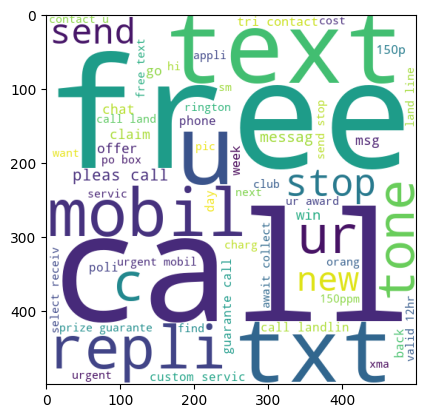

In [62]:
plt.Figure(figsize=(20,10))
plt.imshow(spam_wc)

In [63]:
ham_wc=wc.generate(df[df['Target']==0]['transformed_text'].str.cat(sep=" "))

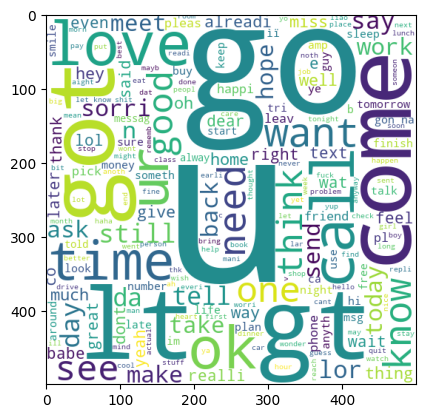

In [64]:
plt.Figure(figsize=(20,10))
plt.imshow(ham_wc)

In [65]:
spam_corpus=[]
for msg in df[df["Target"]==1]["transformed_text"].tolist():
    for word in msg.split():
        spam_corpus.append(word)

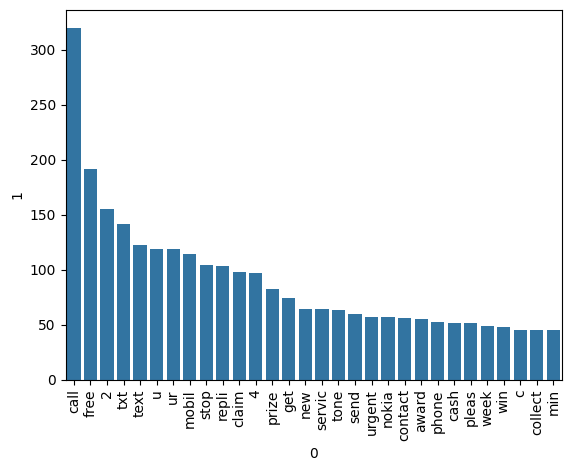

In [70]:
from collections import Counter
temp=pd.DataFrame(Counter(spam_corpus).most_common(30))
sns.barplot(x=temp[0],y=temp[1])
plt.xticks(rotation='vertical')
plt.show()

In [77]:
ham_corpus=[]
for msg in df[df["Target"]==0]["transformed_text"].tolist():
    for word in msg.split():
        ham_corpus.append(word)

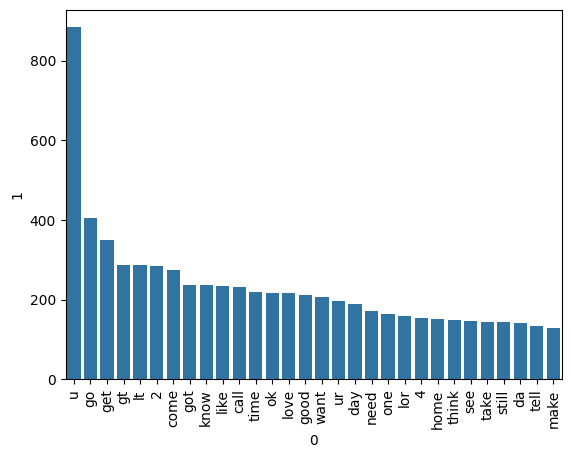

In [78]:
from collections import Counter
temp_ham=pd.DataFrame(Counter(ham_corpus).most_common(30))
sns.barplot(x=temp_ham[0],y=temp_ham[1])
plt.xticks(rotation='vertical')
plt.show()